In [2]:
from circuits.templates import IQPAnsatz , AngleAnsatz
from circuits.constructor import CircuitBuilder
from feature_maps.templates import AngleEmbedding, NeuralEmbedding
from pennylane import numpy as np
import pennylane as qml
import torch

#### 1) Angle embedding + IQPAnsatz

[(48,)]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)] [ 3.00652465 -0.72616349  2.80623501 -0.42102811 -1.42933263 -2.54967452
  3.11402281  1.3943544 ]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)] [ 1.85791079 -1.21465207 -2.5037287   2.35534132 -2.07583424  2.07127433
  3.08683708  1.58596654]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)] [ 2.46461598 -0.90636614 -0.96874888  1.60641656  2.0460804  -0.06180881
  0.92468865  0.17631834]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)] [ 3.00652465 -0.72616349  2.80623501 -0.42102811 -1.42933263 -2.54967452
  3.11402281  1.3943544 ]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)] [ 1.85791079 -1.21465207 -2.5037287   2.35534132 -2.07583424  2.07127433
  3.08683708  1.58596654]
[(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)] [ 2.46461598 -0.90636614 -0.96874888  1.60641656  2.0460804  -0.06180881
  0.92468865  0.17631834]


tensor([0.06255739, 0.03300659, 0.11935057, 0.03827329, 0.05246715,
        0.02701057, 0.05847959, 0.03002087, 0.05944888, 0.03489864,
        0.15821485, 0.05578541, 0.01968773, 0.02741983, 0.1669484 ,
        0.05643024], requires_grad=True)

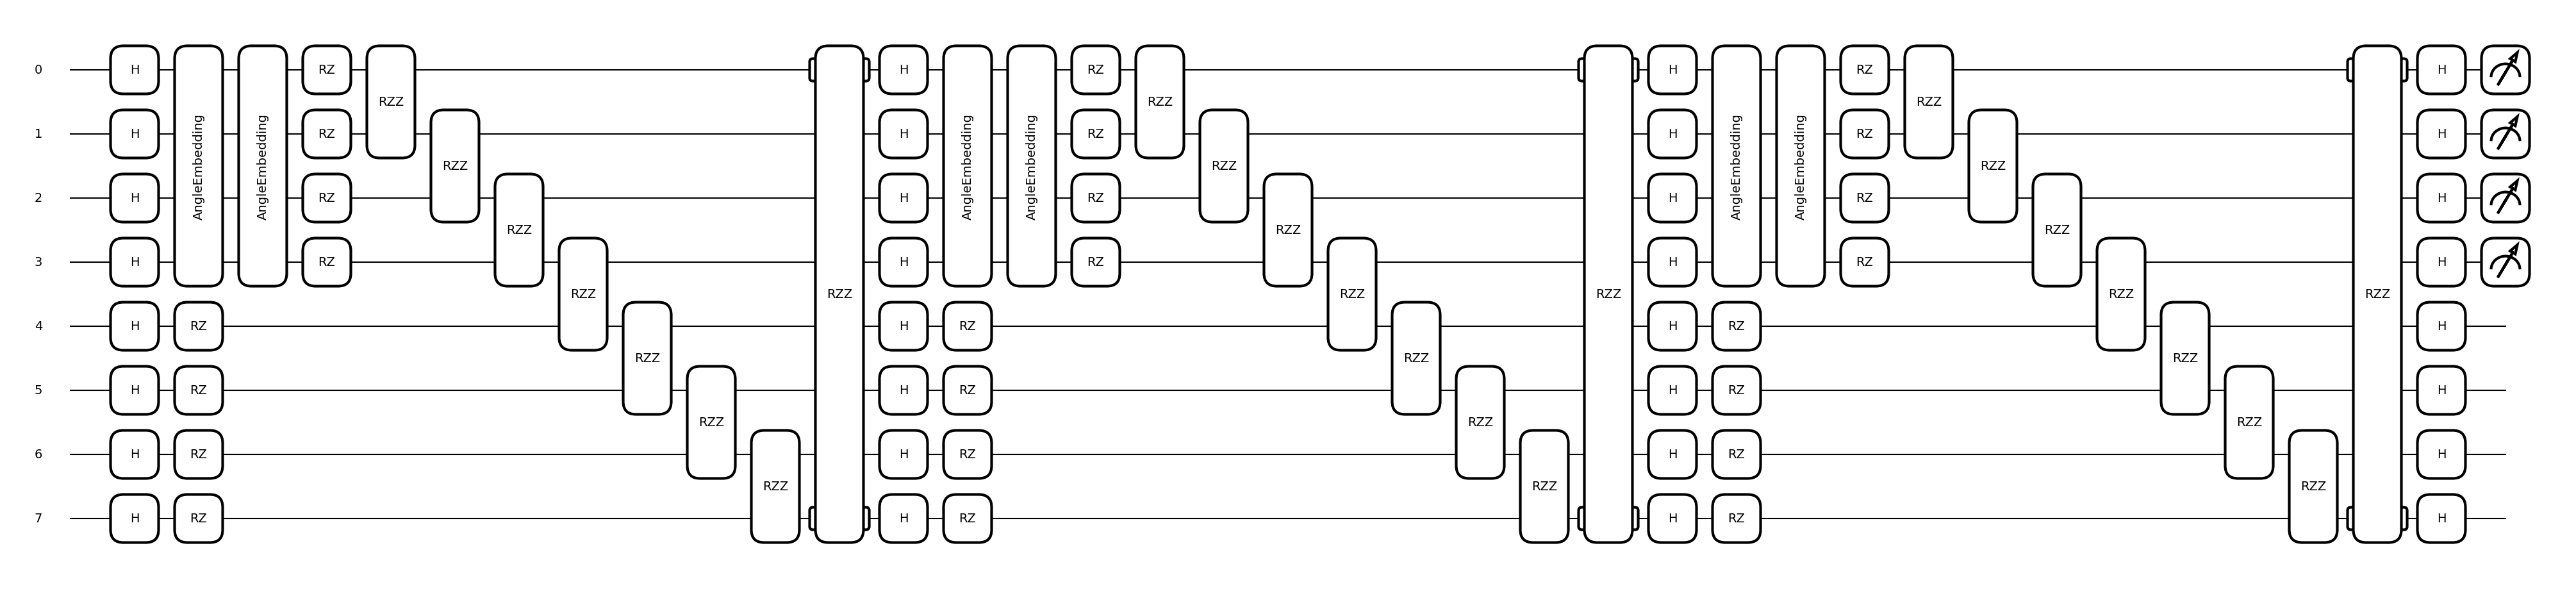

In [ ]:

fm = AngleEmbedding(features=4, n_qubits=4, rotations="Z", input_scaling=False)
#fm = AngleEmbedding(n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"])

iqp = IQPAnsatz(n_qubits=8, pattern="ring", n_layers=3, feature_map=fm, reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()   # → [(4,), (6,)] for a 4-qubit ring (6 edges)
print(shapes)
# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]
)  # 4 params for the qubits

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=8)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(circuit)(inputs=np.random.random(4), params=params)
qnode = builder.compile()

# 4. Run the circuit
qnode(inputs=np.random.random(4), params=params)

#### 2) Angle embedding + Arbitrary Angle ansatz 

tensor([0.04158055, 0.0610782 , 0.07166937, 0.04929629, 0.02505434,
        0.08582657, 0.01006778, 0.01283023, 0.01529266, 0.03413254,
        0.13739382, 0.24061351, 0.00637149, 0.1121629 , 0.08076918,
        0.01586056], requires_grad=True)

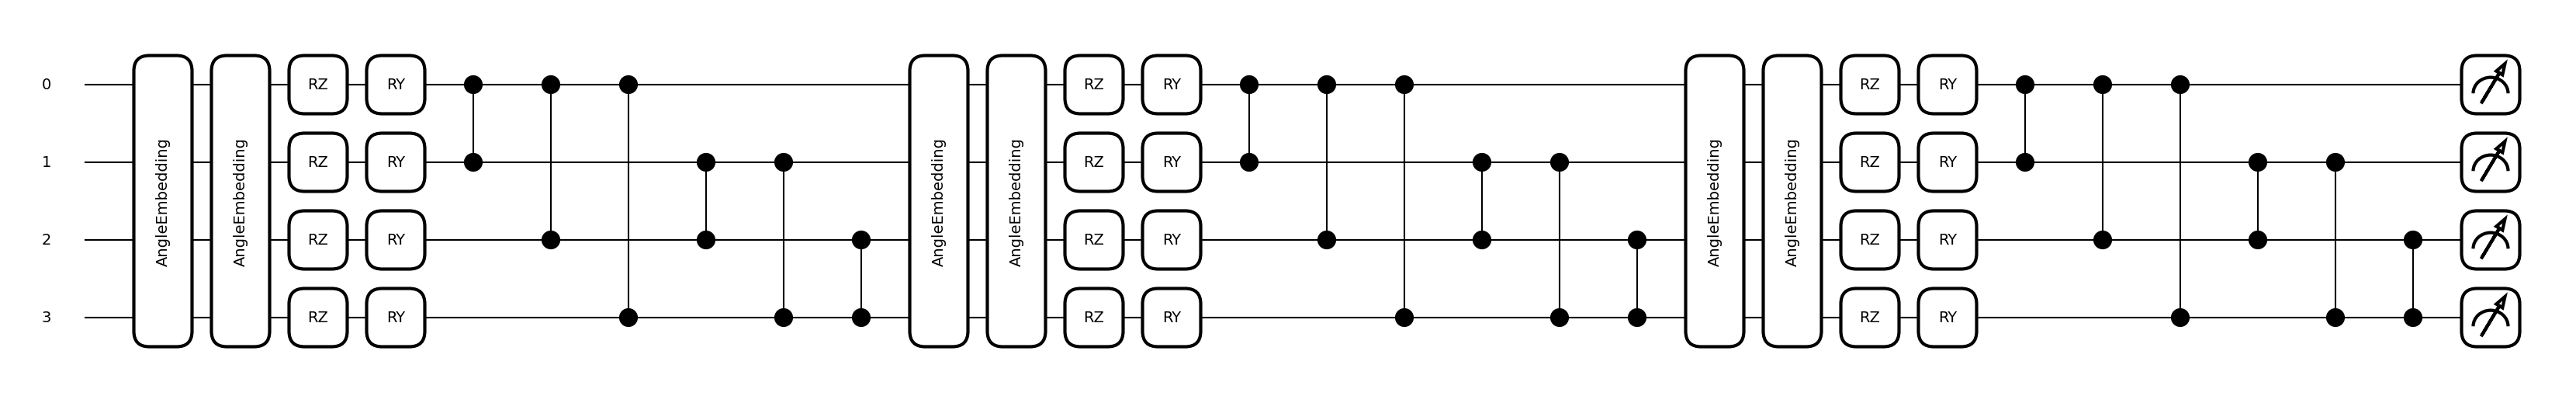

In [ ]:
fm = AngleEmbedding(features=4, n_qubits=4, rotations="YZ", input_scaling=True)
#fm = AngleEmbedding(features=4 , n_qubits=4, rotations=["YX 0 1", "Y 1", "ZX 0 2", "ZZZ 0 1 2"], input_scaling=True)

#iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=3, feature_map=fm, reuploading=True)
iqp = AngleAnsatz(n_qubits=4, n_layers=3 , rotations = "ZY" , feature_map=fm , include_imprimitive=True, imprimitive = "CZ" , imprimitive_pattern="all_to_all", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()   # → [(4,), (6,)] for a 4-qubit ring (6 edges)
# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[1]
)  # 4 params for the qubits

input_scaling_params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]
)  # 4 params for the qubits

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=16)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(circuit)(inputs=np.random.random(4), params=params , input_scaling_params = input_scaling_params)

qnode = builder.compile()
# 4. Run the circuit
qnode(inputs=np.random.random(4), params=params , input_scaling_params = input_scaling_params)

tensor([0.11478224, 0.0443882 , 0.04161279, 0.18405354, 0.03203704,
        0.14059709, 0.12145803, 0.04578872, 0.02338184, 0.02089035,
        0.01101929, 0.06999146, 0.00694913, 0.02188884, 0.0629342 ,
        0.05822725], requires_grad=True)

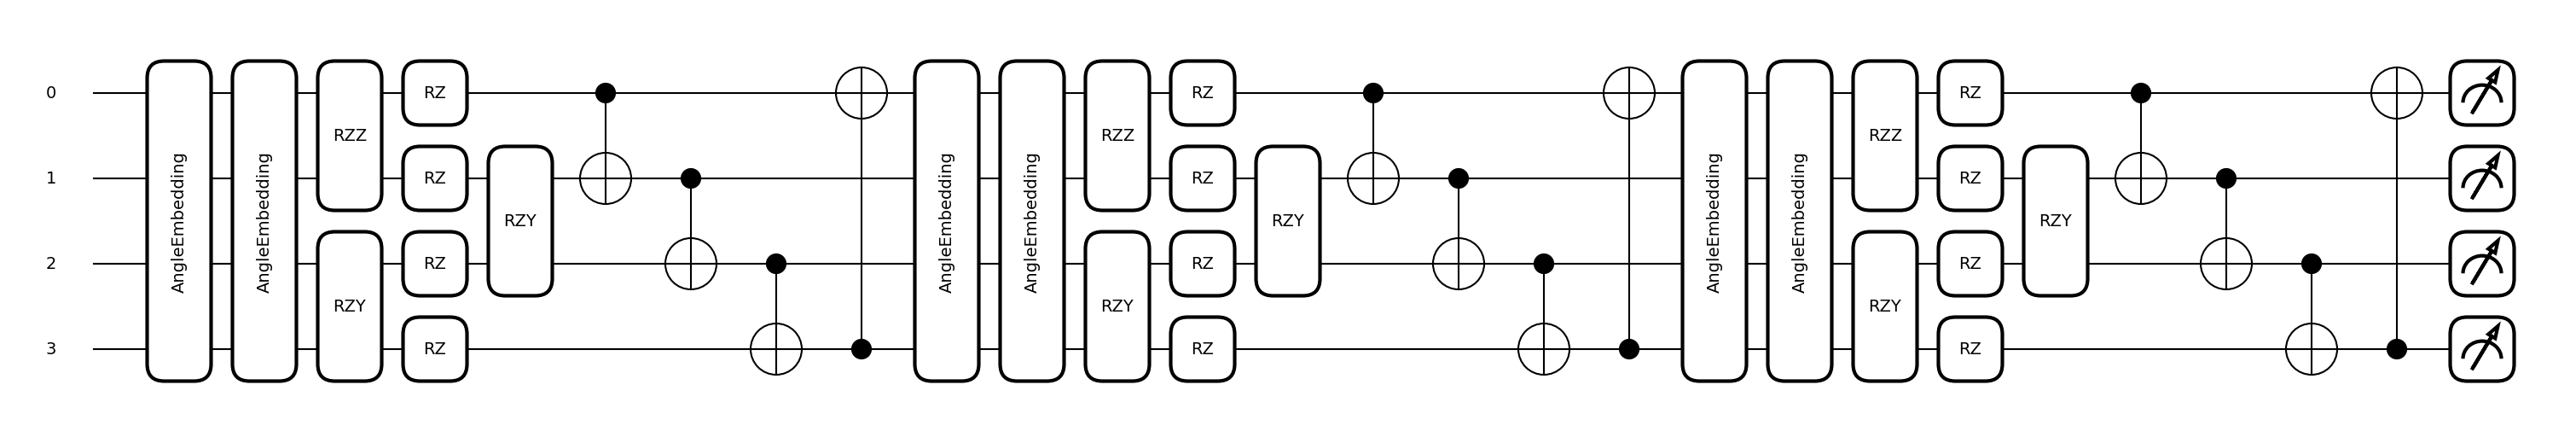

In [10]:

fm = AngleEmbedding(features=4, n_qubits=4, rotations="YZ")
#fm = AngleEmbedding(n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"])

#iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=3, feature_map=fm, reuploading=True)
iqp = AngleAnsatz(n_qubits=4, n_layers=3 , rotations = ["ZZ 0 1" , "ZY 2 3", "Z 0" , "Z 1", "Z 2" , "Z 3" , "ZY 1 2"] , feature_map=fm , include_imprimitive=True, imprimitive = "CNOT" , imprimitive_pattern="ring", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()   # → [(4,), (6,)] for a 4-qubit ring (6 edges)
# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]
)  # 4 params for the qubits

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=16)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(circuit)(inputs=np.random.random(4), params=params)

qnode = builder.compile()


# 4. Run the circuit
inpts = np.random.random(4)
qnode(inputs=inpts, params=params)

#### 3) creating a torch layer with the ansatz
```python

In [ ]:
qlayer = builder.create_torchlayer( params = torch.tensor(params, requires_grad=True) )

In [ ]:
qlayer(torch.tensor(inpts))

#### 4) test input scaling models

tensor([1.39304182e-01, 6.74019592e-02, 3.16790162e-02, 1.07164171e-01,
        5.20870504e-02, 4.95272964e-05, 9.56029594e-02, 1.13056293e-01,
        1.76476053e-03, 3.25602341e-02, 1.20550371e-02, 1.29762578e-02,
        1.33027140e-01, 1.27828763e-01, 6.16833516e-02, 1.17592969e-02], requires_grad=True)

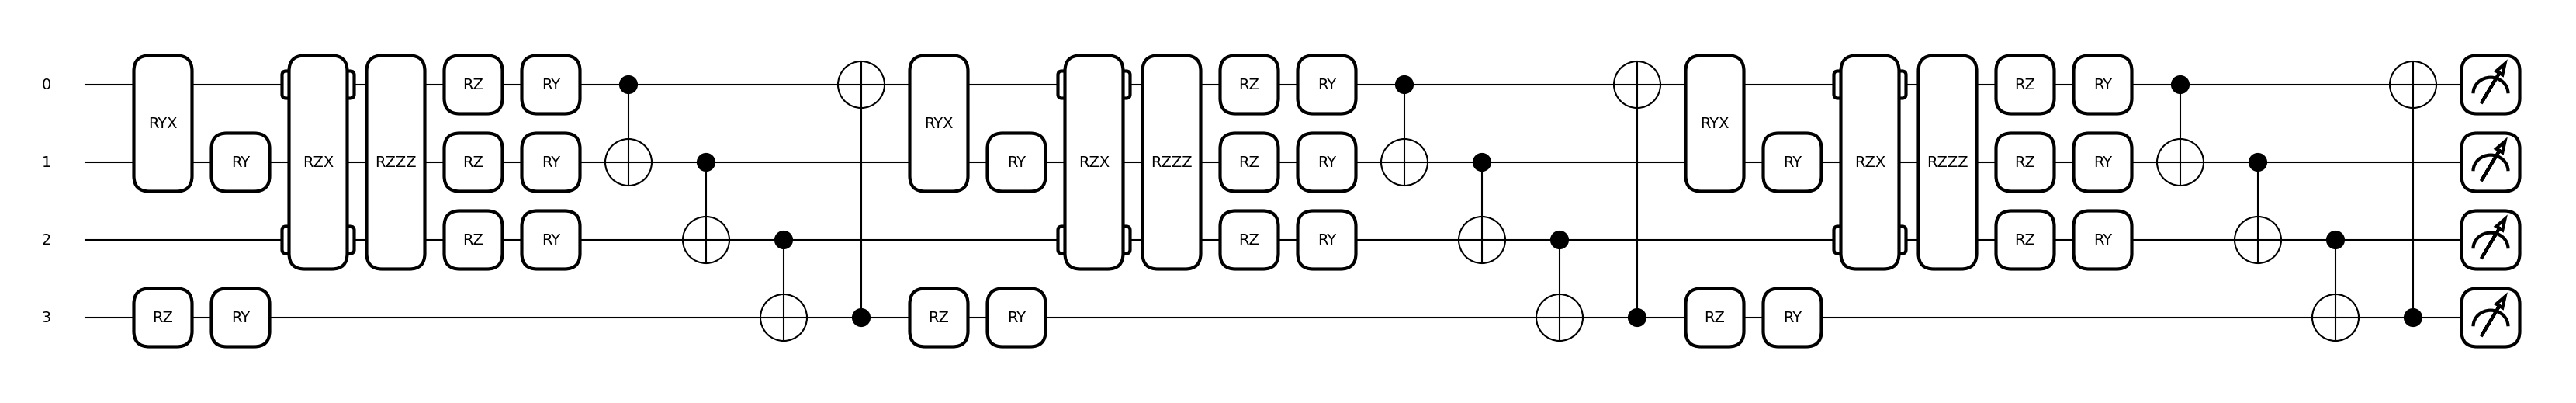

In [ ]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="YZ", input_scaling=True)
fm = AngleEmbedding(features=4, n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"] , input_scaling=True)

#iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=3, feature_map=fm, reuploading=True)
iqp = AngleAnsatz(n_qubits=4, n_layers=3 , rotations = "ZY" , feature_map=fm , include_imprimitive=True, imprimitive = "CNOT" , imprimitive_pattern="ring", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  

# Create a params array matching that shape
input_scaling_params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]
) 

# Create input scaling params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[1]
) 

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=4)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(circuit)(inputs=np.random.random(4), input_scaling_params=input_scaling_params, params=params)

qnode = builder.compile()
# 4. Run the circuit

inpts = np.random.random(4)
qnode(inputs=inpts, input_scaling_params=input_scaling_params, params=params)

In [ ]:
qlayer = builder.create_torchlayer( params = torch.tensor(params, requires_grad=True) , input_scaling_params = torch.tensor(input_scaling_params, requires_grad=True) )


In [ ]:
qlayer(torch.tensor(inpts))

tensor([1.3930e-01, 6.7402e-02, 3.1679e-02, 1.0716e-01, 5.2087e-02, 4.9527e-05,
        9.5603e-02, 1.1306e-01, 1.7648e-03, 3.2560e-02, 1.2055e-02, 1.2976e-02,
        1.3303e-01, 1.2783e-01, 6.1683e-02, 1.1759e-02], dtype=torch.float64,
       grad_fn=<ViewBackward0>)

tensor([0.09498411, 0.03117785, 0.08060699, 0.19673521, 0.04389855,
        0.00076971, 0.00735417, 0.00405098, 0.01023535, 0.18521828,
        0.03370299, 0.02819497, 0.01166569, 0.06607068, 0.07254836,
        0.13278612], requires_grad=True)

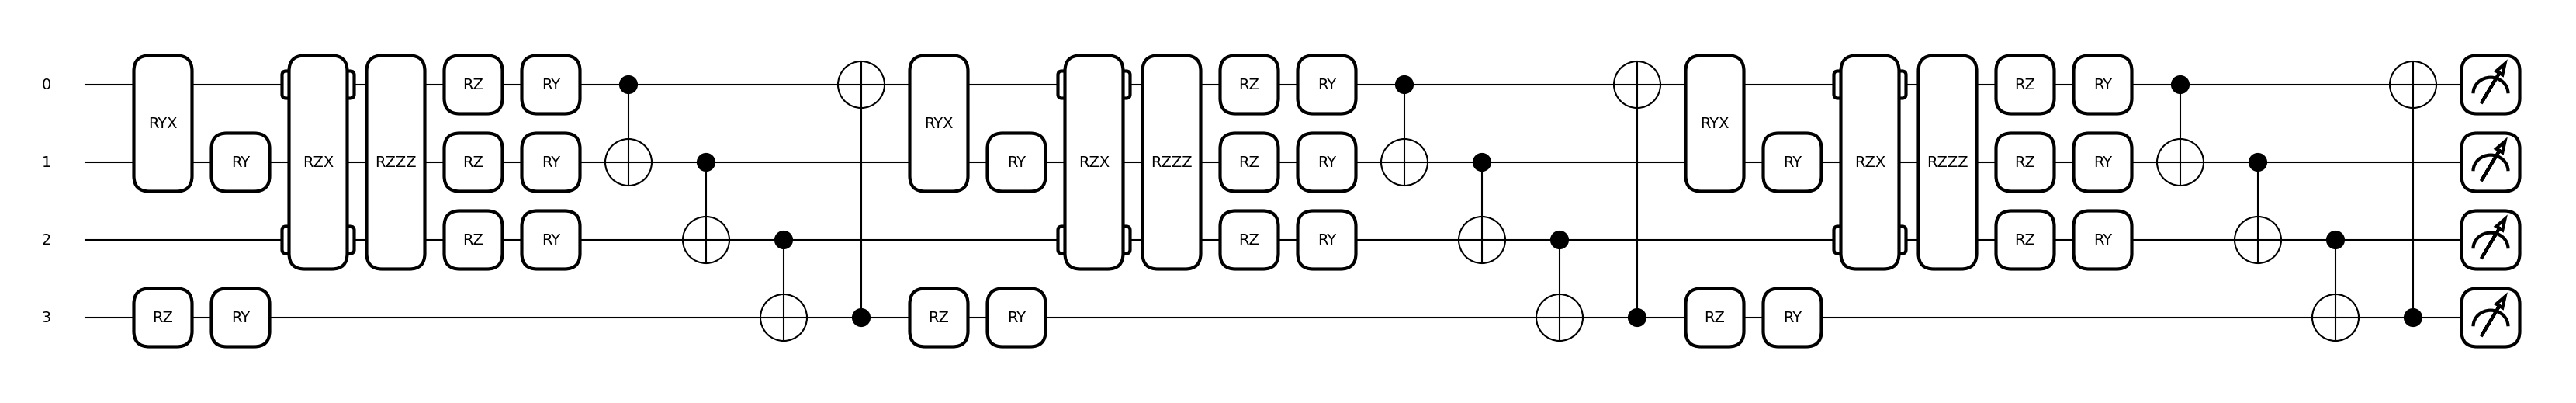

In [ ]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="YZ", input_scaling=True)
fm = AngleEmbedding(features=4, n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"] , input_scaling=False)

#iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=3, feature_map=fm, reuploading=True)
iqp = AngleAnsatz(n_qubits=4, n_layers=3 , rotations = "ZY" , feature_map=fm , include_imprimitive=True, imprimitive = "CNOT" , imprimitive_pattern="ring", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]
) 

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=4)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(circuit)(inputs=np.random.random(4), params=params)

qnode = builder.compile()
# 4. Run the circuit

inpts = np.random.random(4)
qnode(inputs=inpts, params=params)

In [ ]:
qlayer = builder.create_torchlayer( params = torch.tensor(params, requires_grad=True))


In [ ]:
qlayer(torch.tensor(inpts))

tensor([0.0950, 0.0312, 0.0806, 0.1967, 0.0439, 0.0008, 0.0074, 0.0041, 0.0102,
        0.1852, 0.0337, 0.0282, 0.0117, 0.0661, 0.0725, 0.1328],
       dtype=torch.float64, grad_fn=<ViewBackward0>)

tensor([0.26980554, 0.04243271, 0.00778749, 0.00375397, 0.0485993 ,
        0.03358117, 0.02072039, 0.02143305, 0.18640323, 0.0088111 ,
        0.18652604, 0.03915824, 0.0950492 , 0.00059608, 0.0234884 ,
        0.01185409], requires_grad=True)

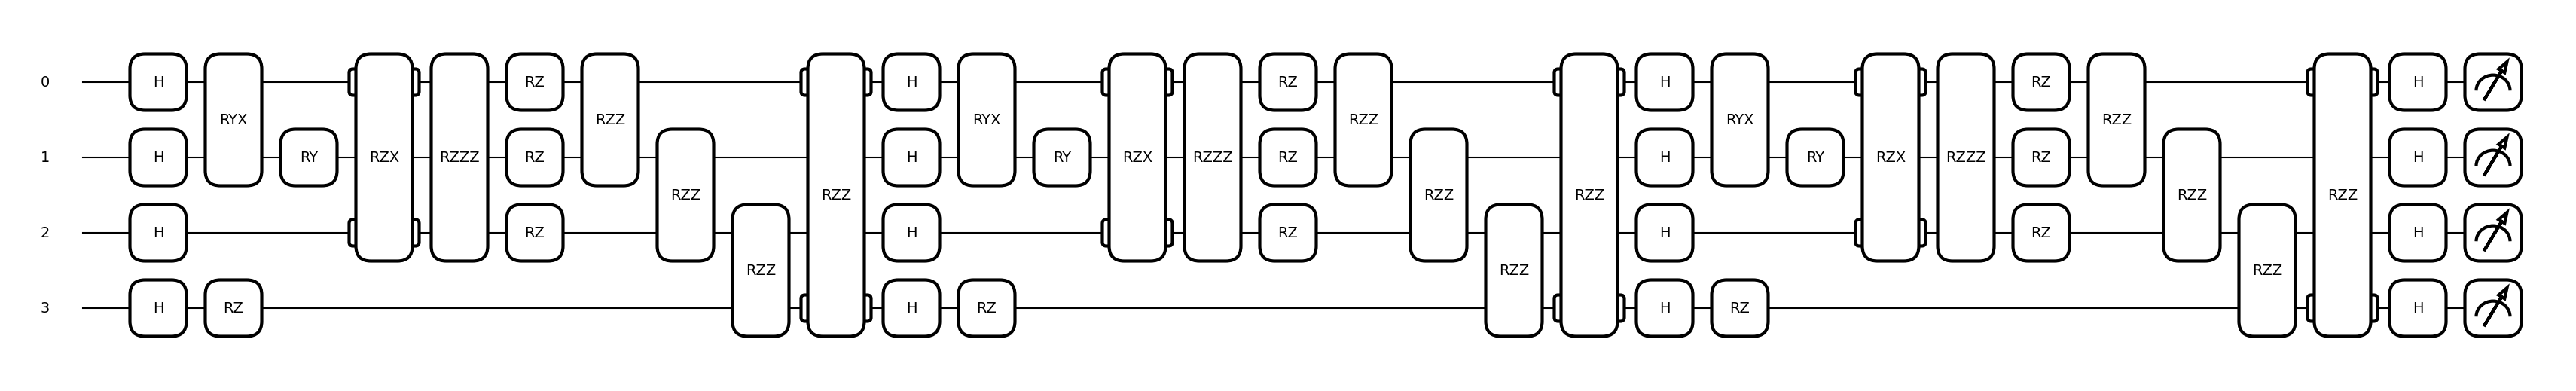

In [3]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="Z", input_scaling=True)
fm = AngleEmbedding(features=4 , n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"], input_scaling=False)

iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=3, feature_map=fm, reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()   
# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]
) 

#input_scaling_params = np.random.uniform(
 #   low=-np.pi, high=np.pi, size=shapes[0]
#)  
# Create a params array matching that shape
# 3. Build your circuit
builder = CircuitBuilder(n_qubits=4)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(circuit)(inputs=np.random.random(4), params=params)#, input_scaling_params=None)
qnode = builder.compile()

inpts = np.random.random(4)
# 4. Run the circuit
qnode(inputs=inpts, params=params)#, input_scaling_params=input_scaling_params)

In [ ]:
qlayer = builder.create_torchlayer( params = torch.tensor(params, requires_grad=True))#, input_scaling_params = torch.tensor(input_scaling_params, requires_grad=True) )


In [ ]:
qlayer(torch.tensor(inpts))

tensor([0.0316, 0.0112, 0.0636, 0.0302, 0.0328, 0.0334, 0.0534, 0.1321, 0.0065,
        0.0103, 0.2031, 0.1458, 0.0537, 0.0672, 0.0858, 0.0393],
       dtype=torch.float64, grad_fn=<ViewBackward0>)

tensor([0.0032127 , 0.1124489 , 0.01642197, 0.02402244, 0.02148914,
        0.01834037, 0.00597151, 0.04620681, 0.16182359, 0.09491934,
        0.02658304, 0.1664047 , 0.24903168, 0.02696814, 0.02123767,
        0.00491801], requires_grad=True)

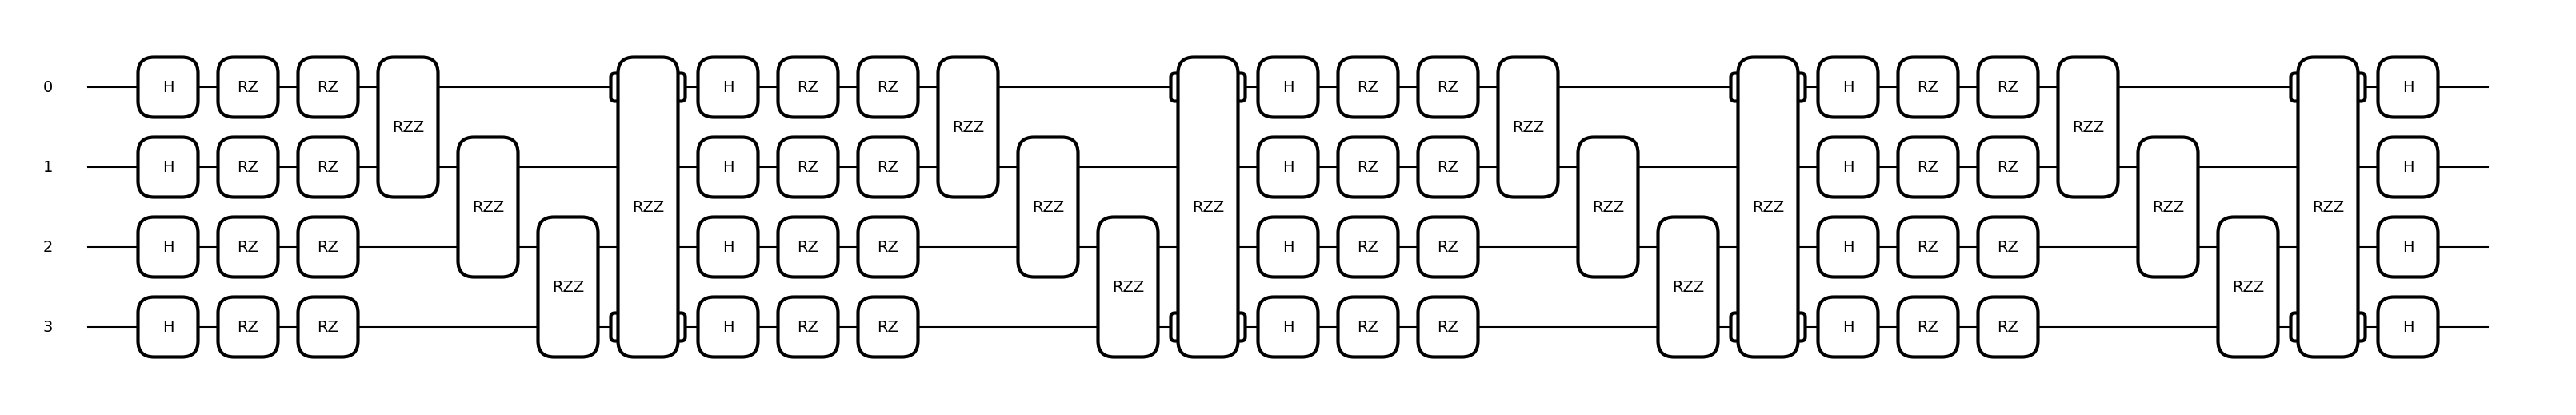

In [ ]:

fm = NeuralEmbedding(features=4, n_qubits=4, rotations="Z")
#fm = AngleEmbedding(features=4, n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"] , input_scaling=False)

iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=4, feature_map=fm, reuploading=True)
#iqp = AngleAnsatz(n_qubits=4, n_layers=1 , rotations = ["ZZ 0 1" , "ZZ 0 2"] , feature_map=fm , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="all_to_all", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[1]  
) 

input_scaling_params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]  
)


# 3. Build your circuit
builder = CircuitBuilder(n_qubits=4)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()

qml.draw_mpl(builder.ansatz, show_all_wires=True, show_all_operations=True)(inputs=np.random.random(4), params=params, input_scaling_params=input_scaling_params)

qnode = builder.compile()
# 4. Run the circuit

inpts = np.random.random(4)
qnode(inputs=inpts, input_scaling_params=input_scaling_params, params=params)



[0.08169925 0.04774477 0.19005266 0.02349652 0.12516869 0.00189654
 0.03407097 0.03408623 0.1789774  0.04690307 0.09044196 0.03982138
 0.00976347 0.06325439 0.02940242 0.00322028]


(<Figure size 3200x600 with 1 Axes>, <Axes: >)

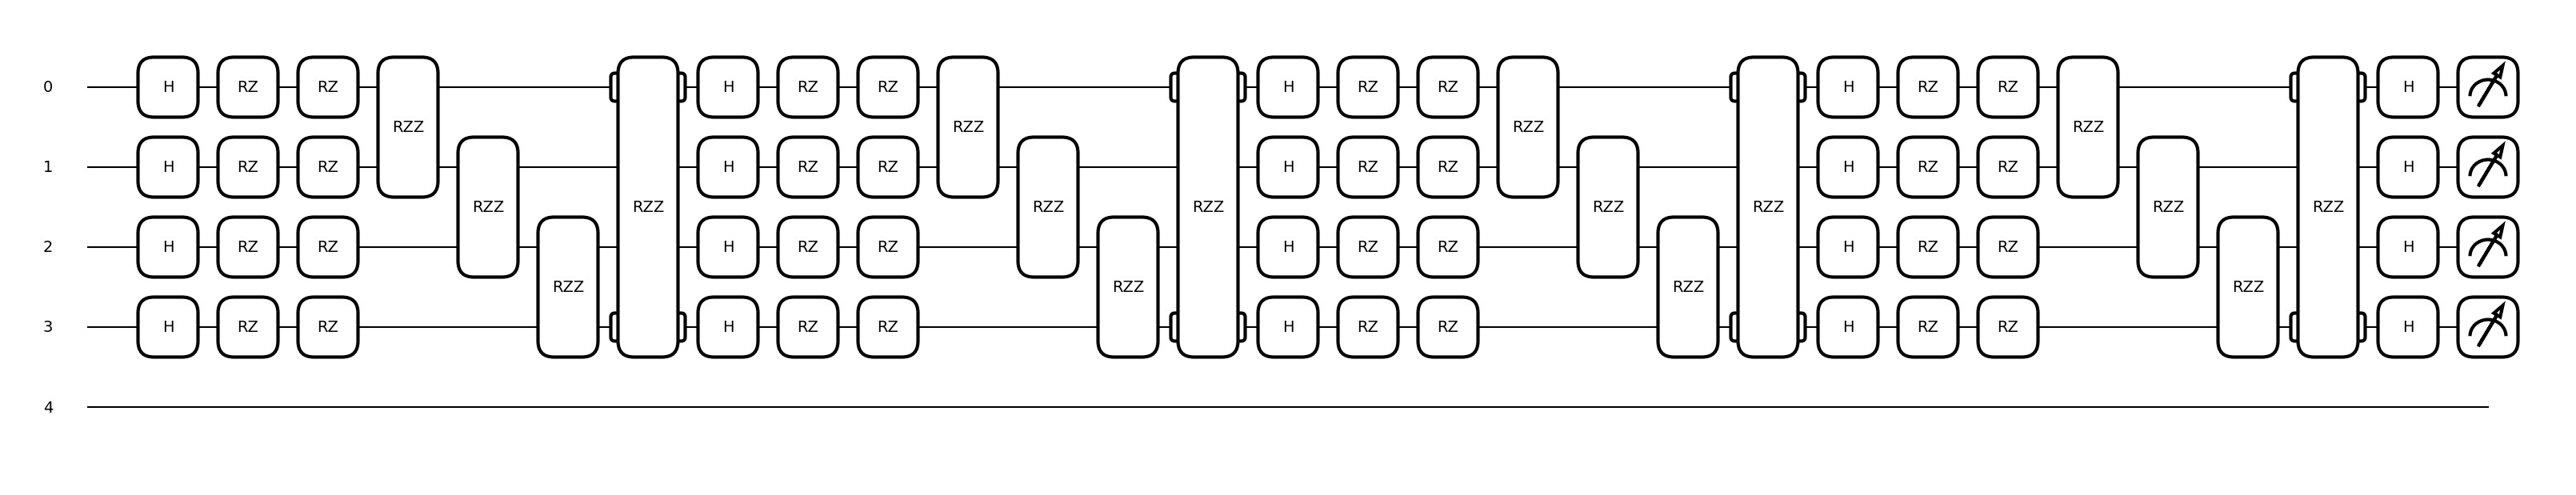

In [2]:

fm = NeuralEmbedding(features=4, n_qubits=4, rotations="Z",input_scaling=True)
#fm = AngleEmbedding(features=4, n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"] , input_scaling=False)

iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=4, feature_map=fm, reuploading=True)
#iqp = AngleAnsatz(n_qubits=4, n_layers=1 , rotations = ["ZZ 0 1" , "ZZ 0 2"] , feature_map=fm , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="all_to_all", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[1]  
) 

input_scaling_params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]  
)


# 3. Build your circuit
builder = CircuitBuilder(n_qubits=4)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build()


qnode = builder.compile()
# 4. Run the circuit

inpts = np.random.random(4)
print(qnode(inputs=inpts, input_scaling_params=input_scaling_params, params=params))

qml.draw_mpl(qnode, show_all_wires=True, show_all_operations=True)(inputs=np.random.random(4), params=params, input_scaling_params=input_scaling_params)


In [3]:
qlayer = builder.create_torchlayer( params = torch.tensor(params, requires_grad=True), input_scaling_params=torch.tensor(input_scaling_params, requires_grad=True))


print(input_scaling_params)
print(qlayer.input_scaling_params)

[-1.5225373   0.9501354  -2.044953   -1.85408728 -1.73761356 -1.48304728
  1.4009548  -0.51473513 -1.7706441  -0.7374711   2.8223603   0.71171509
 -0.48989154 -1.15050338  2.37671384 -2.31513356 -1.50948998  0.05913687
 -3.10701239  2.35056027 -3.04798756 -3.06866889 -2.86552956  1.39849866
 -0.84876885 -0.72700651 -0.77855029 -1.81617921 -2.22247588 -0.10112852
  1.19516462  0.61136103  2.43973837  0.27359793 -1.28637814  1.01744328
  1.10846482 -1.90644385 -1.62905651 -0.05099497  2.26192615  1.89972947
  0.39951927 -2.62748789  1.93260885 -1.04586505 -0.25978176 -2.14357055
  1.93539534  2.66288381 -0.66636011 -2.43685935 -3.10747247  1.0315931
 -0.50037452  0.73464771 -2.38761205 -0.60210696 -2.83582364 -2.26014912
 -0.7030728   2.90938225  0.87803742  1.38916423]
Parameter containing:
tensor([-1.5225,  0.9501, -2.0450, -1.8541, -1.7376, -1.4830,  1.4010, -0.5147,
        -1.7706, -0.7375,  2.8224,  0.7117, -0.4899, -1.1505,  2.3767, -2.3151,
        -1.5095,  0.0591, -3.1070,  2.3

[0.04963916 0.07277796 0.05605703 0.07227659 0.06713516 0.11500813
 0.01228825 0.0450662  0.07462327 0.14201707 0.05806055 0.04552021
 0.02832039 0.05123211 0.02929444 0.08068346]


(<Figure size 4800x1000 with 1 Axes>, <Axes: >)

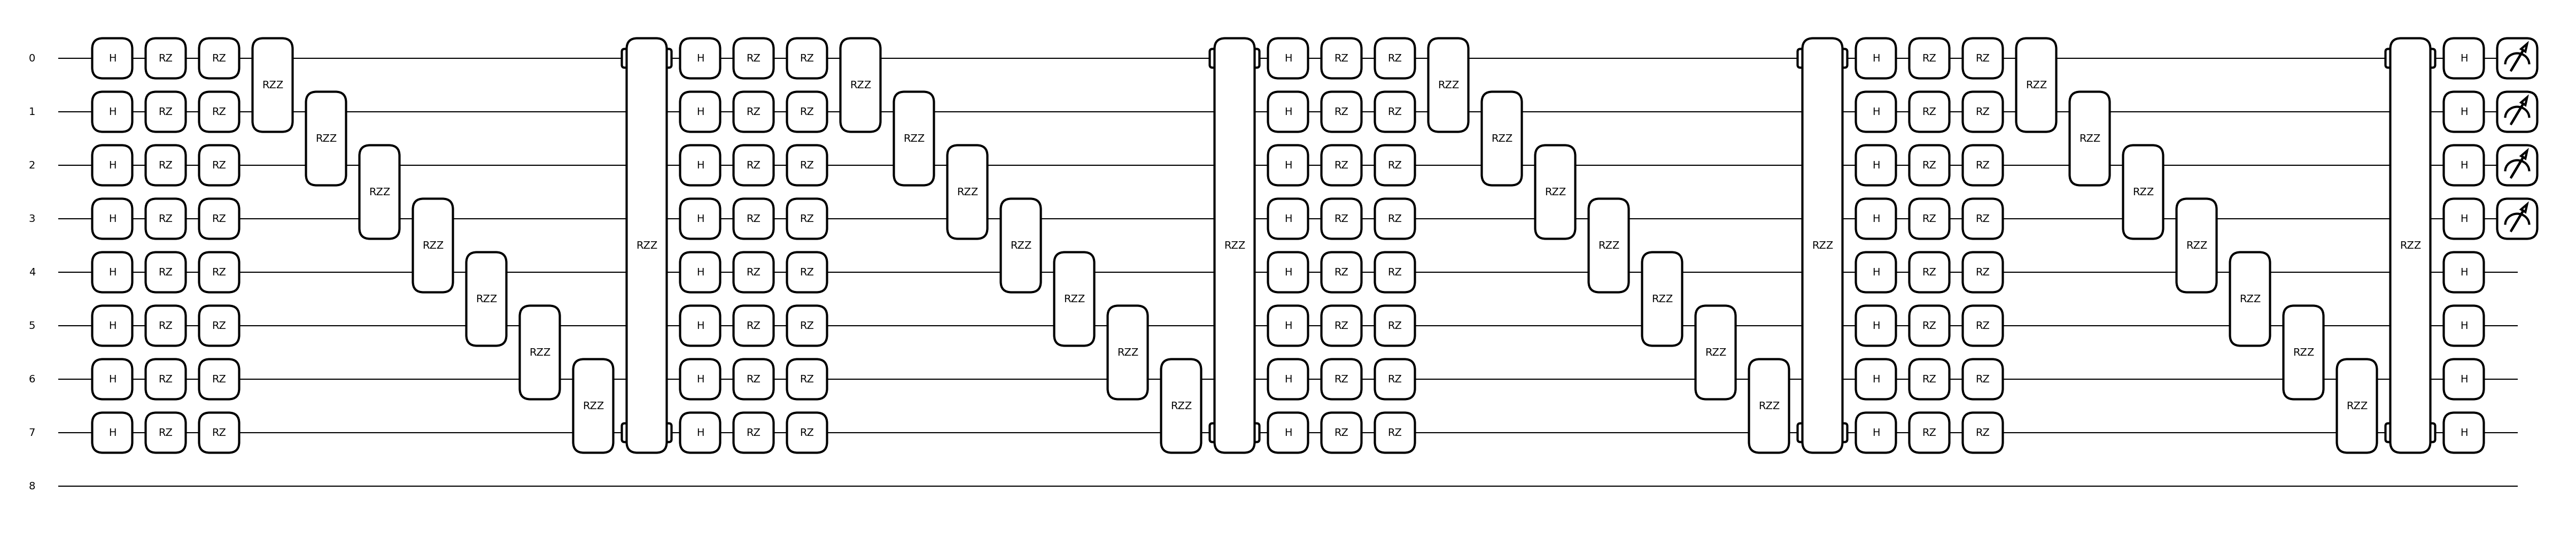

In [2]:

fm = NeuralEmbedding(features=4, n_qubits=8, rotations="Z",input_scaling=True)
#fm = AngleEmbedding(features=4, n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"] , input_scaling=False)

iqp = IQPAnsatz(n_qubits=8, pattern="ring", n_layers=4, feature_map=fm, reuploading=True)
#iqp = AngleAnsatz(n_qubits=4, n_layers=1 , rotations = ["ZZ 0 1" , "ZZ 0 2"] , feature_map=fm , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="all_to_all", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[1]  , requires_grad=True
) 

input_scaling_params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]  , requires_grad=True
)


# 3. Build your circuit
builder = CircuitBuilder(n_qubits=8)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build_adaptive()


qnode = builder.compile()
# 4. Run the circuit

inpts = np.random.random(4)
print(qnode(inputs=[inpts,[0,1,2,3]], input_scaling_params=input_scaling_params, params=params))

qml.draw_mpl(qnode, show_all_wires=True, show_all_operations=True)(inputs=[np.random.random(4),[0,1,2,3]], params=params, input_scaling_params=input_scaling_params)


(<Figure size 4800x1000 with 1 Axes>, <Axes: >)

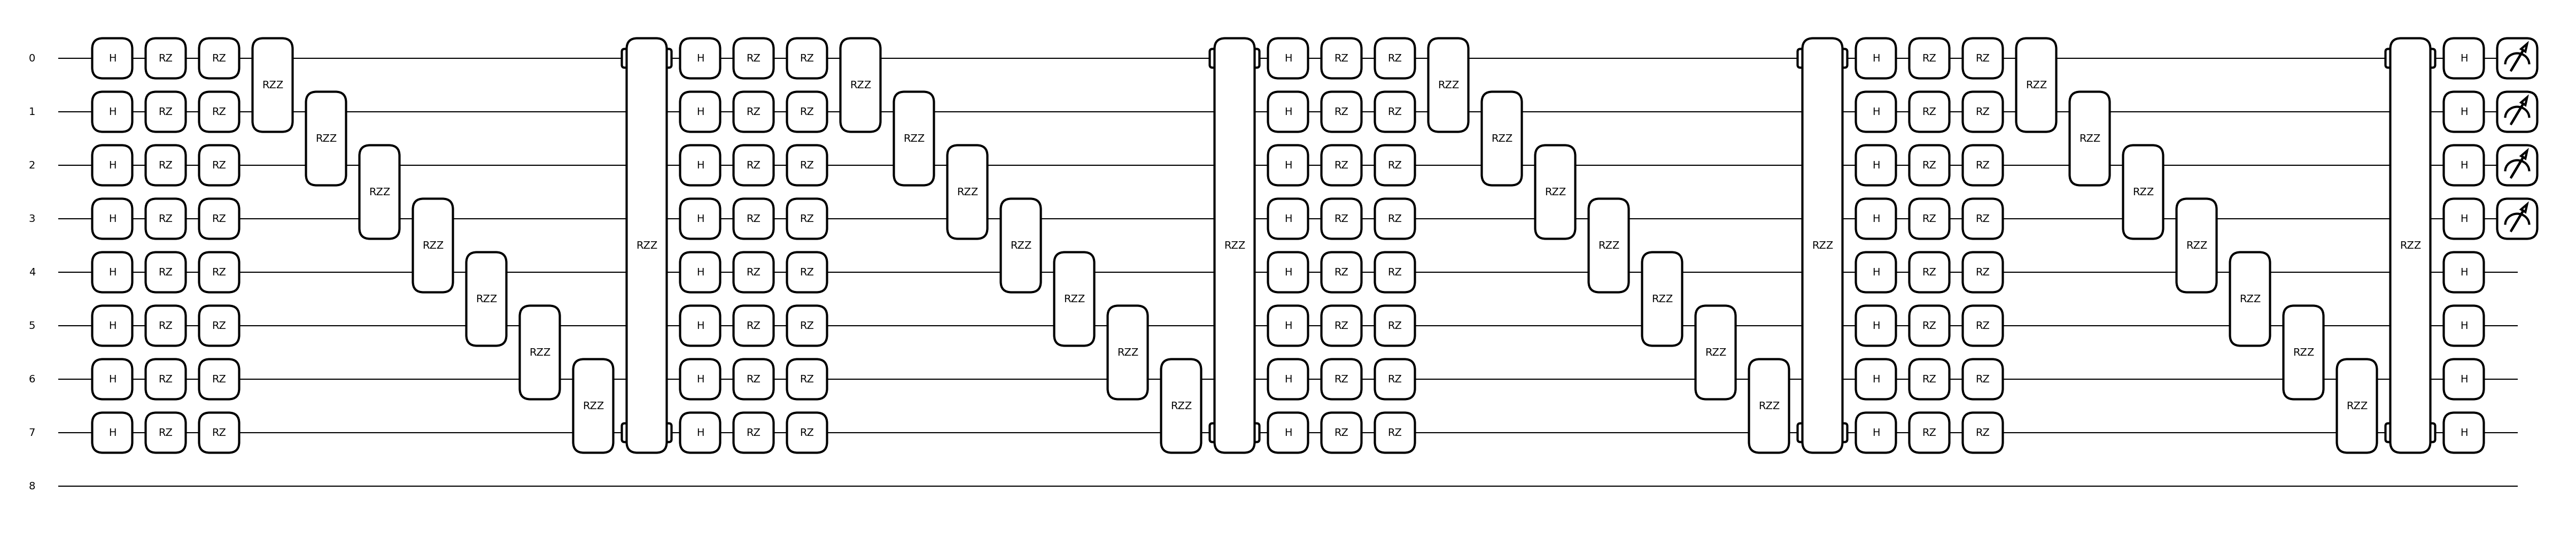

In [3]:
qml.draw_mpl(qnode, show_all_wires=True, show_all_operations=True)(inputs=[np.random.random(4),list(range(int(np.ceil(np.log2(8)**1.2))))], params=params, input_scaling_params=input_scaling_params)


In [4]:

fm = NeuralEmbedding(features=4, n_qubits=8, rotations="Z",input_scaling=True)
#fm = AngleEmbedding(features=4, n_qubits=4, rotations=["YX 01", "Y 1", "ZX 02", "ZZZ 012"] , input_scaling=False)

iqp = IQPAnsatz(n_qubits=8, pattern="ring", n_layers=4, feature_map=fm, reuploading=True)
#iqp = AngleAnsatz(n_qubits=4, n_layers=1 , rotations = ["ZZ 0 1" , "ZZ 0 2"] , feature_map=fm , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="all_to_all", reuploading=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[1]  , requires_grad=True
) 

input_scaling_params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]  , requires_grad=True
)


# 3. Build your circuit
builder = CircuitBuilder(n_qubits=8)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
builder.set_measurement("probs",wires=range(4))  # or whichever measurement you want
circuit = builder.build_adaptive(for_torchlayer=True)


qnode = builder.compile()
# 4. Run the circuit


qlayer = builder.create_torchlayer( params = torch.tensor(params, requires_grad=True), input_scaling_params=torch.tensor(input_scaling_params, requires_grad=True))


print(input_scaling_params)
print(qlayer.input_scaling_params)

[-1.24960638 -1.13247817  1.84002913  0.42400439 -2.14459856  1.85105541
  2.60621574  1.75811756  1.97172146  0.55341229 -2.76818378  2.07083758
  2.20108109  1.55631968  1.36494635  1.09791765  0.78221036 -2.33179643
  1.47453876 -0.01070463 -2.61668098 -2.21157184  0.83976129 -3.12832743
 -0.05451774  1.43192046  1.14941584  2.10162639  1.12392899 -1.11234884
  2.08374973  0.56840078 -0.82659206 -1.43318468  2.14938583  1.11585412
  0.8555491  -1.5793351  -0.69767984 -2.37313968  2.35695549 -0.62258142
  1.81770485  1.53121748  0.69142545 -1.97529979  2.88679917  0.9076539
 -1.20860991  2.58444295 -1.31653522 -1.58776907  3.12257538  1.83830971
  0.32716794 -2.01028703 -0.87795406  1.16357639 -2.8073855   2.28850586
 -3.04580876  2.98067791  0.40886264 -1.15215973 -0.13209232  0.10845832
 -1.4563912   2.89110269 -0.80414819  2.87489969  2.44070591  2.95394494
  0.51351437 -3.0277699   2.59034013  0.19846051 -0.9346985  -0.13815435
  2.48786122  0.41834498  2.11546608 -2.23695029 -3.

In [ ]:
qlayer(torch.concatenate((torch.rand(4),torch.tensor([0,1]))))

tensor([0.3727, 0.1495, 0.3281, 0.1498], grad_fn=<ToCopyBackward0>)